## Finding a surrogate model against the given closed-box API

**Task:** Identify a local model that is able to approximatly mimic the model behind the closed-box API. That is needed as we want to develop some adverserial attacks against the API. (We also want to keep the query budget against the API small)

$\rightarrow$ Overal goal: Identify what the classes "class1"/"class2" and "class3"/"class4" correspond to

**Given:**
- We know that the API model is some kind of CLIP model with some linear head attached
- We have the API endpoint, which is not rate limited
- We know that the class pairs class1/class2 and class3/class4 are closely related (each pair sums to 1)
  - Hints to two heads heads upon the CLIP model
- The model returns 17 decimal places for each probability $\rightarrow$ it makes sense to use logits (`ln(p2/p1)` and `ln(p3/p4)`) instead of the pure probabilities
- Furthermore, given an input the API always returns the same output


**Approach:** We therefore split this task into several subtasks:
1. Try to identify the backbone network
2. Learn two MLP heads (for the two connected class pairs) upon the chosen network

## 1. Setup

In [1]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
%pip install faiss-cpu
%pip install numpy pandas
%pip install datasets
%pip install transformers
%pip install scikit-learn
%pip install matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip
c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip

Note: you may need to restart the kernel to use updated packages.



c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip
c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, base64, json, time, sqlite3, hashlib, io
import numpy as np
import torch, faiss
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from datasets import load_dataset
from transformers import CLIPModel, CLIPProcessor
from transformers.modeling_outputs import BaseModelOutputWithPooling
from tqdm import tqdm
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
CLIP_MODEL_POOL = ["openai/clip-vit-large-patch14",
                   "openai/clip-vit-base-patch16",
                   "laion/CLIP-ViT-H-14-laion2B-s32B-b79K"]
# CLIP_MODEL_POOL = ["openai/clip-vit-base-patch16"] # TODO: remove just for local testing on laptop

# data
IMAGE_DATASET_HG = "j-reber/imagenet_reduced_trainingset-single_sample"
IMAGE_CACHE = Path(".cache/imagenet")
BATCH_SIZE  = 64

# API
ENDPOINT = "https://wstud-mmml26-classification.web.webis.de/predict"
CLASSES  = ["class1", "class2", "class3", "class4"] # no other classes are allowed to use for endpoint

# query budget
N_TEST   = 100           # size of testset
N_SEED   = 200           # seed per kmeans
ROUNDS   = 10             # number of al rounds
BATCH    = 64           # queries per round
STRATEGY = "al"          # either al or random

# AL internals
COMMITTEE = 5
BOUNDARY_WEIGHT = 0.5
PREFILTER = 10
MIN_INTERVAL = 0.3

RIDGE_ALPHAS = np.logspace(-6, 2, 17)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

IMAGE_CACHE.mkdir(parents=True, exist_ok=True)
print(f"[device] {DEVICE}")

[device] cuda


In [4]:
# Some helper methods

def load_image(path):
    img = Image.open(path).convert("RGB")
    img.thumbnail((1024, 1024))
    return img

def to_png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()

def to_logits(resp):
    c = resp["classes"]
    p = np.array([float(c[k]) for k in CLASSES])
    p = np.clip(p, 1e-300, 1.0)
    z = np.array([np.log(p[1] / p[0]),
                  np.log(p[2] / p[3])])
    return z, p

def r2(y, yhat):
    # calculate coefficient of determination
    return 1 - ((y - yhat) ** 2).sum(0) / ((y - y.mean(0)) ** 2).sum(0)

def sign_acc(y, yhat):
    return (np.sign(y) == np.sign(yhat)).mean(0)

In [5]:
# Define the endpoint query class

class Endpoint:
    def __init__(self, url, cache_path, min_interval=0.3, timeout=60, retries=4):
        self.s = requests.Session()
        self.url, self.min_interval, self.timeout, self.retries = url, min_interval, timeout, retries
        self.db = sqlite3.connect(str(cache_path))
        self.db.execute("CREATE TABLE IF NOT EXISTS cache (key TEXT PRIMARY KEY, resp TEXT)")
        self.n_remote = 0
        self._last = 0.0

    def predict(self, png, classes=tuple(CLASSES), use_cache=True):
        payload = {"image": base64.b64encode(png).decode()}
        if classes is not None:
            payload["classes"] = list(classes)
        key = hashlib.sha1(png + json.dumps(payload.get("classes")).encode()).hexdigest()
        if use_cache:
            row = self.db.execute("SELECT resp FROM cache WHERE key=?", (key,)).fetchone()
            if row:
                return json.loads(row[0])
        err = None
        for attempt in range(self.retries):
            wait = self.min_interval - (time.time() - self._last)
            if wait > 0:
                time.sleep(wait)
            self._last = time.time()
            try:
                r = self.s.post(self.url, json=payload, timeout=self.timeout)
            except requests.RequestException as e:
                err = e; time.sleep(2 ** attempt); continue
            self.n_remote += 1
            if r.status_code == 429 or r.status_code >= 500:
                err = f"HTTP {r.status_code}"; time.sleep(2 ** attempt); continue
            if r.status_code != 200:
                raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")
            data = r.json()
            if use_cache:
                self.db.execute("INSERT OR REPLACE INTO cache VALUES (?, ?)", (key, json.dumps(data)))
                self.db.commit()
            return data
        raise RuntimeError(f"Endpoint not reachable: {err}")

endpoint = Endpoint(ENDPOINT, IMAGE_CACHE / "cache.sqlite", MIN_INTERVAL)

### 1.1 Load dataset from HF

In [6]:
manifest = IMAGE_CACHE / "manifest.jsonl"
img_dir  = IMAGE_CACHE / "images"

def build():
    ds = load_dataset(IMAGE_DATASET_HG, split="train")
    names = ds.features["label"].names
    img_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    with manifest.open("w") as f:
        for new_id, ex in enumerate(ds):
            path = img_dir / f"{new_id:06d}.jpg"
            ex["image"].convert("RGB").save(path, quality=95)
            row = {"id": new_id, "path": str(path),
                   "label_id": int(ex["label"]), "label": names[int(ex["label"])]}
            rows.append(row); f.write(json.dumps(row) + "\n")
    return rows

def load():
    return [json.loads(l) for l in manifest.read_text().splitlines()]

samples = load() if manifest.exists() else build()
PATHS = [s["path"] for s in samples]
print(len(samples), "Images")

1000 Images


In [7]:
# load CLIP models and embedd dataset

def load_clip(name):
    model = CLIPModel.from_pretrained(name).to(DEVICE).eval()
    proc  = CLIPProcessor.from_pretrained(name)
    return model, proc

@torch.no_grad()
def embed_all(name, paths, bs=BATCH_SIZE):
    model, proc = load_clip(name)
    feats = []
    for k in tqdm(range(0, len(paths), bs), desc=name.split("/")[-1]):
        imgs = [load_image(p) for p in paths[k:k+bs]]
        x = proc(images=imgs, return_tensors="pt").to(DEVICE)
        f = model.get_image_features(**x)
        if isinstance(f, BaseModelOutputWithPooling):   # handle change introd in transformer 5
            f = f.pooler_output
        f = torch.nn.functional.normalize(f, dim=-1)
        feats.append(f.cpu().numpy())
    del model, proc
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return np.concatenate(feats).astype("float32")

EMB = {}
for name in CLIP_MODEL_POOL:
    f = IMAGE_CACHE / f"emb_{name.replace('/', '_')}.npy"
    if not f.exists():
        np.save(f, embed_all(name, PATHS))
    EMB[name] = np.load(f)

N = len(next(iter(EMB.values())))
print("pool:", N, {k.split("/")[-1]: v.shape[1] for k, v in EMB.items()})

pool: 1000 {'clip-vit-large-patch14': 768, 'clip-vit-base-patch16': 512, 'CLIP-ViT-H-14-laion2B-s32B-b79K': 1024}


## 2. Approach Step 1 - Find best match for CLIP model from pool

In [8]:
LABELS = {}

def query(idxs):
    for i in map(int, idxs):
        if i in LABELS:
            continue
        z, _ = to_logits(endpoint.predict(to_png_bytes(load_image(PATHS[i]))))
        LABELS[i] = z

def Zof(idxs):
    return np.stack([LABELS[int(i)] for i in idxs])

In [9]:
def make_model(kind, seed=SEED, alpha=None):
    if kind == "ridge":
        return Ridge(alpha=alpha) if alpha is not None else RidgeCV(alphas=RIDGE_ALPHAS)
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(256,), alpha=1e-2,
                                      learning_rate_init=1e-3, max_iter=1500, random_state=seed))

def cv_r2(X, Z, kind, k=5):
    pred = np.zeros_like(Z)
    for tr, te in KFold(k, shuffle=True, random_state=SEED).split(X):
        pred[te] = make_model(kind).fit(X[tr], Z[tr]).predict(X[te])
    return r2(Z, pred)

def compare_backbones(train_idx, with_mlp=True):
    Z = Zof(train_idx)
    res = {}
    for name, E in EMB.items():
        res[name] = {"ridge": cv_r2(E[train_idx], Z, "ridge")}
        if with_mlp:
            res[name]["mlp"] = cv_r2(E[train_idx], Z, "mlp")
    return res

def print_table(res):
    print(f"{'backbone':40s}  {'ridge h1/h2':>14s}   {'mlp h1/h2':>14s}")
    for n, r in res.items():
        m = r.get("mlp", [np.nan, np.nan])
        print(f"{n:40s}  {r['ridge'][0]:6.3f} {r['ridge'][1]:6.3f}   {m[0]:6.3f} {m[1]:6.3f}")

def kmeans_pick(X, cand, k, score=None, seed=SEED):
    cand = np.asarray(cand); k = min(k, len(cand))
    Xc = np.ascontiguousarray(X[cand], dtype=np.float32)
    km = faiss.Kmeans(Xc.shape[1], k, niter=25, seed=seed, spherical=True,
                      verbose=False, min_points_per_centroid=1)
    km.train(Xc)
    if score is None:
        index = faiss.IndexFlatIP(Xc.shape[1]); index.add(Xc)
        _, I = index.search(km.centroids, 1)
        pick = list(dict.fromkeys(I[:, 0].tolist()))
        order = np.random.default_rng(seed).permutation(len(cand))
    else:
        _, A = km.index.search(Xc, 1); A = A[:, 0]
        pick = [int(m[np.argmax(score[m])]) for c in range(k) if len(m := np.where(A == c)[0])]
        order = np.argsort(-score)
    chosen = set(pick)
    pick += [int(j) for j in order if j not in chosen][:k - len(pick)]
    return cand[np.array(pick[:k])]

In [10]:
# Split dataset in train and test to assess performance of surrogate model

JOINT = np.hstack([EMB[n] for n in CLIP_MODEL_POOL]) / np.sqrt(len(CLIP_MODEL_POOL))

TEST = rng.choice(N, N_TEST, replace=False)
query(TEST)
TEST = np.array([i for i in TEST if i in LABELS])

cand = np.setdiff1d(np.arange(N), TEST)
SEED_IDX = kmeans_pick(JOINT, cand, N_SEED, seed=SEED)
query(SEED_IDX)
TRAIN = [int(i) for i in SEED_IDX if int(i) in LABELS]

print(f"queries: {endpoint.n_remote} | test {len(TEST)} | train {len(TRAIN)}")

queries: 300 | test 100 | train 200


In [11]:
# compare backbones

BB_RES = compare_backbones(TRAIN)
print_table(BB_RES)

def pick_best(res):
    return max(res, key=lambda n: max(res[n]["ridge"].mean(),
                                      res[n].get("mlp", res[n]["ridge"]).mean()))

BEST = pick_best(BB_RES)
r = BB_RES[BEST]
KIND = "mlp" if r["mlp"].mean() > r["ridge"].mean() + 0.02 else "ridge"
print(f"\nbest backbone: {BEST}  |  head: {KIND}")

backbone                                     ridge h1/h2        mlp h1/h2
openai/clip-vit-large-patch14              0.136  0.379   -0.058  0.177
openai/clip-vit-base-patch16               0.232  0.382   -0.041  0.153
laion/CLIP-ViT-H-14-laion2B-s32B-b79K      0.316  0.464    0.005  0.100

best backbone: laion/CLIP-ViT-H-14-laion2B-s32B-b79K  |  head: ridge


## 3. Approach Step 2 - Refine Surrogate Head

In [12]:
def fit_committee(X, Z, kind, K, seed):
    r = np.random.default_rng(seed)
    alpha = RidgeCV(alphas=RIDGE_ALPHAS).fit(X, Z).alpha_ if kind == "ridge" else None
    out = []
    for k in range(K):
        b = r.integers(0, len(X), len(X))
        out.append(make_model(kind, seed=seed + k, alpha=alpha).fit(X[b], Z[b]))
    return out

def evaluate(model, E):
    Zt = Zof(TEST); P = model.predict(E[TEST])
    return {"r2": r2(Zt, P).tolist(), "sign_acc": sign_acc(Zt, P).tolist(),
            "rmse": np.sqrt(((Zt - P) ** 2).mean(0)).tolist()}

HISTORY = []
def log_round(rnd):
    E = EMB[BEST]
    model = make_model(KIND).fit(E[TRAIN], Zof(TRAIN))
    ev = evaluate(model, E)
    HISTORY.append({"round": rnd, "queries": endpoint.n_remote, "n_train": len(TRAIN),
                    "backbone": BEST, "kind": KIND, **ev})
    print(f"round {rnd:2d} | q {endpoint.n_remote:4d} | train {len(TRAIN):4d} | "
          f"R2 {ev['r2'][0]:.3f}/{ev['r2'][1]:.3f} | sign {ev['sign_acc'][0]:.3f}/{ev['sign_acc'][1]:.3f}")
    return model

model = log_round(0)
for rnd in range(1, ROUNDS + 1):
    E = EMB[BEST]
    taken = set(TRAIN) | set(TEST.tolist())
    cand = np.array([i for i in range(N) if i not in taken])
    if len(cand) == 0:
        break
    if STRATEGY == "random":
        new = rng.choice(cand, min(BATCH, len(cand)), replace=False)
    else:
        members = fit_committee(E[TRAIN], Zof(TRAIN), KIND, COMMITTEE, SEED + 100 * rnd)
        P = np.stack([m.predict(E[cand]) for m in members])
        mu, sd = P.mean(0), P.std(0)
        score = (sd / (sd.mean(0) + 1e-9)).sum(1) + BOUNDARY_WEIGHT * np.exp(-np.abs(mu) / 2).max(1)
        top = np.argsort(-score)[:PREFILTER * BATCH]
        new = kmeans_pick(E, cand[top], BATCH, score=score[top], seed=SEED + rnd)
    query(new)
    TRAIN += [int(i) for i in new if int(i) in LABELS]

    res = compare_backbones(TRAIN, with_mlp=False)
    best_now = max(res, key=lambda n: res[n]["ridge"].mean())
    if best_now != BEST and KIND == "ridge":
        print(f"  backbone switch: {BEST} -> {best_now}")
        BEST = best_now
    model = log_round(rnd)

print("\nridge R2 after all rounds:")
print_table(compare_backbones(TRAIN, with_mlp=False))

round  0 | q  300 | train  200 | R2 0.462/0.410 | sign 0.910/0.780
round  1 | q  364 | train  264 | R2 0.474/0.437 | sign 0.880/0.760
round  2 | q  428 | train  328 | R2 0.551/0.472 | sign 0.900/0.740
round  3 | q  492 | train  392 | R2 0.568/0.472 | sign 0.900/0.710
round  4 | q  556 | train  456 | R2 0.632/0.491 | sign 0.900/0.720
round  5 | q  620 | train  520 | R2 0.641/0.502 | sign 0.920/0.720
round  6 | q  684 | train  584 | R2 0.639/0.508 | sign 0.920/0.760
round  7 | q  748 | train  648 | R2 0.654/0.501 | sign 0.930/0.760
round  8 | q  812 | train  712 | R2 0.669/0.497 | sign 0.930/0.750
round  9 | q  876 | train  776 | R2 0.686/0.540 | sign 0.920/0.760
round 10 | q  940 | train  840 | R2 0.676/0.557 | sign 0.910/0.780

ridge R2 after all rounds:
backbone                                     ridge h1/h2        mlp h1/h2
openai/clip-vit-large-patch14              0.523  0.535      nan    nan
openai/clip-vit-base-patch16               0.589  0.575      nan    nan
laion/CLIP-ViT-H-

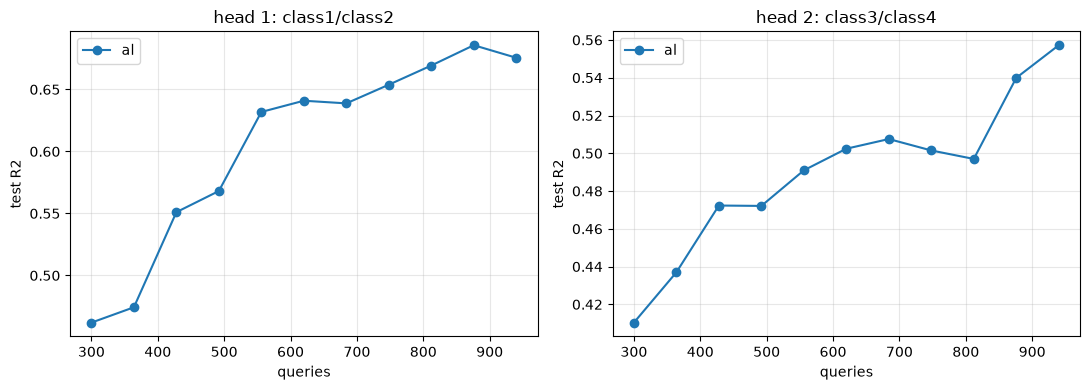

In [13]:
(IMAGE_CACHE / f"history_{STRATEGY}.json").write_text(json.dumps(HISTORY, indent=2))
joblib.dump({"backbone": BEST, "kind": KIND, "model": model,
             "classes": CLASSES, "logits": ["ln(p2/p1)", "ln(p3/p4)"]},
            IMAGE_CACHE / f"surrogate_{STRATEGY}.joblib")


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for f in sorted(IMAGE_CACHE.glob("history_*.json")):
    h = json.loads(f.read_text()); q = [x["queries"] for x in h]
    for ax, head in zip(axes, (0, 1)):
        ax.plot(q, [x["r2"][head] for x in h], marker="o", label=f.stem.replace("history_", ""))
for ax, t in zip(axes, ("head 1: class1/class2", "head 2: class3/class4")):
    ax.set_title(t); ax.set_xlabel("queries"); ax.set_ylabel("test R2"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## For the investigation into the meaning of these classes please see the dictionary attack notebook